In [1]:
import polars as pl
import pandas as pd
import os
import glob
import dns.dnssec
import pyarrow
import dns.name
import matplotlib.pyplot as plt
import seaborn as sns
import tldextract
import re
import os
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.colors as colors
from config import *

### NSEC Distance
* run process_strdistance_*.py to generate raw data
* Plot Figure 3 

In [2]:
datestr = "20260406"
zones = ['com', 'net', 'org', 'umbrella','tranco','radar','majestic']
zone = 'com'
savedir = f"{DATAROOT}/processed/{datestr}/{zone}"

In [3]:
fpath = os.path.join(savedir,f"{datestr}_nsec_namedist.parquet")

In [6]:
df = pd.read_parquet(fpath)

In [7]:
df["QRDist"] = df["QRDist"].map(int)
df["QNDist"] = df["QNDist"].map(int)
df["NRDist"] = df["NRDist"].map(int)

In [8]:
df["Response Status"] = df["status_code"].apply(lambda x: "NXDOMAIN" if x == 3 else "NODATA")

In [9]:
df["Response Status"].value_counts()

Response Status
NODATA      944327
NXDOMAIN    666177
Name: count, dtype: int64

In [10]:
df.loc[df["QNDist"]<10]["QNDist"].value_counts()

QNDist
0    702706
1       423
Name: count, dtype: int64

In [11]:
df.loc[df["QRDist"]<10]["QRDist"].value_counts()

QRDist
0    691864
1     11690
Name: count, dtype: int64

In [12]:
df_nxdom = df[df["status_code"]==3]
df_nodata = df[df["status_code"]==0]

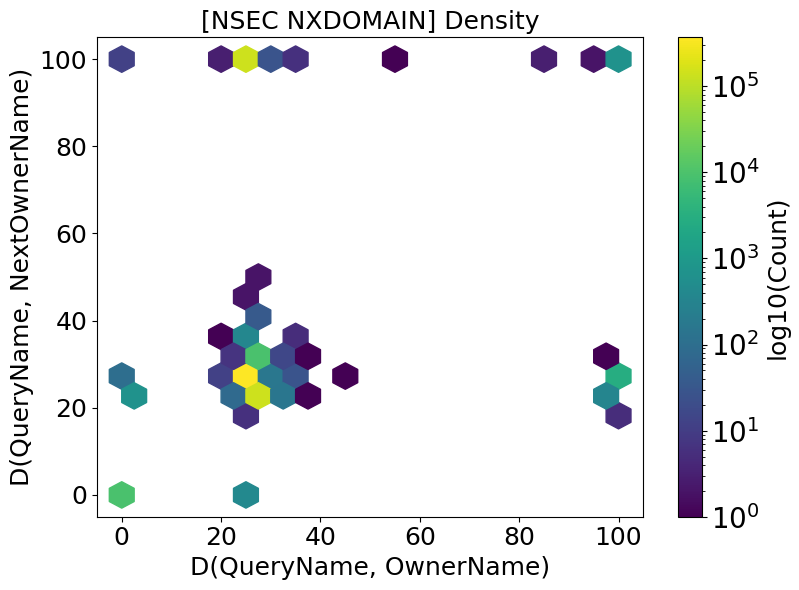

In [13]:
plt.figure(figsize=(8, 6))
# We use a log scale for the count (color) to see small clusters clearly
#subdf = df_nxdom[(df_nxdom["QRDist"]<100) & (df_nxdom["QNDist"] < 100)]
sns.color_palette("viridis", as_cmap=True)
plt.hexbin(df_nxdom['QRDist'], df_nxdom['QNDist'], gridsize=20, bins='log')

#plt.colorbar(label='log10(count)')
plt.xlim([-5,105])
plt.ylim([-5,105])
#plt.xscale("log")
#plt.yscale("log")
plt.xlabel("D(QueryName, OwnerName)", fontsize=18)
plt.ylabel("D(QueryName, NextOwnerName)", fontsize=18)
plt.title("[NSEC NXDOMAIN] Density", fontsize=18)
plt.xticks(fontsize=18)
plt.yticks(fontsize=18)
plt.tight_layout()
cbar = plt.colorbar()
for t in cbar.ax.get_yticklabels():
     t.set_fontsize(20)
cbar.set_label('log10(Count)', fontsize=18)
#plt.savefig("figures/nsec_nxdomain_density.png", dpi=300)
plt.show()

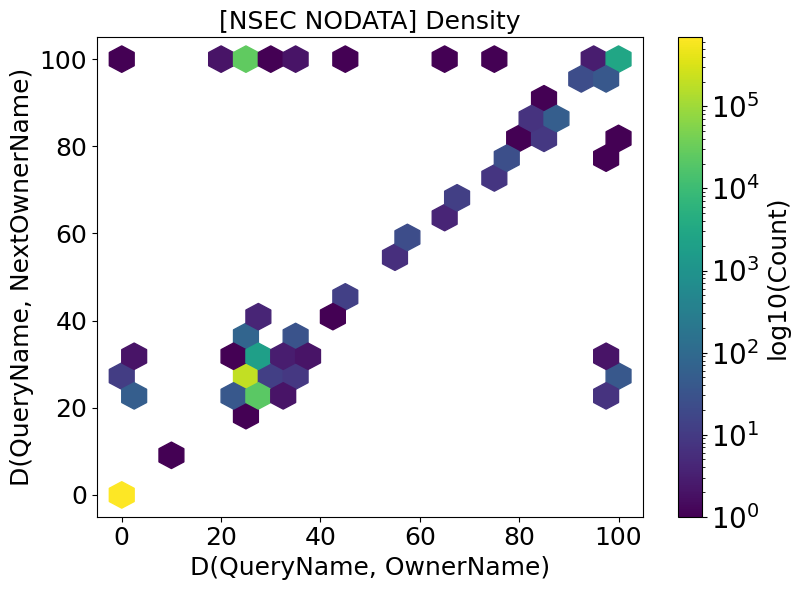

In [14]:
plt.figure(figsize=(8, 6))
# We use a log scale for the count (color) to see small clusters clearly
sns.color_palette("viridis", as_cmap=True)
plt.hexbin(df_nodata['QRDist'], df_nodata['QNDist'], gridsize=20, bins='log')

#plt.colorbar(label='log10(Count)')
plt.xlim([-5,105])
plt.ylim([-5,105])
plt.xlabel("D(QueryName, OwnerName)", fontsize=18)
plt.ylabel("D(QueryName, NextOwnerName)", fontsize=18)
plt.title("[NSEC NODATA] Density", fontsize=18)
plt.xticks(fontsize=18)
plt.yticks(fontsize=18)
plt.tight_layout()
cbar = plt.colorbar()
for t in cbar.ax.get_yticklabels():
     t.set_fontsize(20)
cbar.set_label('log10(Count)', fontsize=18)
#plt.savefig("figures/nsec_nodata_density.png", dpi=300)
plt.show()

### NSEC3 Distance
* Figure 6 in Appendix

In [25]:
datestr = "20260406"
zones = ['com', 'net', 'org', 'umbrella','tranco','radar','majestic']
zone = 'com'
savedir = f"{DATAROOT}/processed/{datestr}/{zone}"

In [16]:
fpath_nsec3 =os.path.join(savedir,f"{datestr}_nsec3_namedist.parquet")

In [17]:
nsec3 = pd.read_parquet(fpath_nsec3)

In [18]:
def calculate_log_distance(distance):
    if distance is None or distance == 'None':
        return None
    if int(distance) <= 0:
        return 0
    # Use log10 for "human readable" scale or log2 for "bit" scale
    return np.log10(float(distance))

In [19]:
def back_to_int(distance):
    if distance is None or distance == 'None':
        return None
    return int(distance)

In [22]:
nsec3["dist_log"] = nsec3["dist"].apply(lambda x: calculate_log_distance(x))

In [23]:
nsec3["dist_int"] = nsec3["dist"].apply(lambda x: back_to_int(x))

In [20]:
nsec3["Response Status"] = nsec3["status_code"].apply(lambda x: "NXDOMAIN" if x == 3 else "NODATA")

/tmp/ipykernel_4043759/2580883867.py:15: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()
/u/yz6me/dnssec/.venv/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


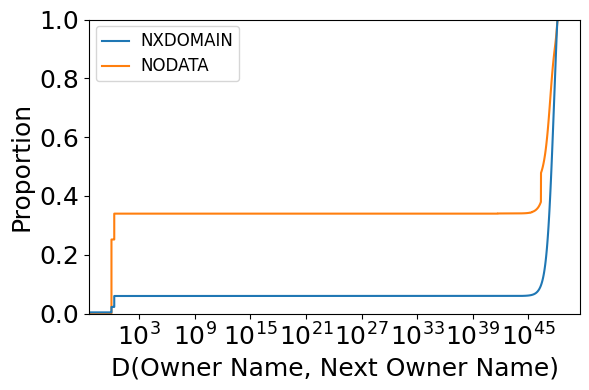

In [24]:
plt.figure(figsize=(6, 4))
ax = sns.ecdfplot(data=nsec3, x="dist_int", hue="Response Status")

# Standard formatting
plt.xlabel("D(Owner Name, Next Owner Name)", fontsize=18) # Added a label for clarity
plt.ylabel("Proportion", fontsize=18)
plt.xticks(fontsize=18)
plt.yticks(fontsize=18)
plt.xscale('log')
# Legend fix
legend = ax.get_legend()
legend.set_title(None) # This removes the title properly
plt.setp(legend.get_texts(), fontsize='12') 
#plt.savefig("res/com_qndist.png", dpi=300)
plt.tight_layout()
plt.show()
